In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.subsampling import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../../data/data_final.csv")

diagnosis_variables = []

with open("../../data/diagnosis_final.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../../data/treatment_final.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

In [3]:
# Find duplicated patients with regional ln recurrence = 1
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False)) #& (survival_dataset['Regional LN recurrence'] == 1)

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [4]:
# Prepare data
data_x = survival_dataset[feature_columns]

data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
# Since every duplicated patient has a consistent event indicator (regional ln recurrence) I can use this method
groups = survival_dataset['PERSON_ID']

In [5]:
sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=data_x, y=survival_dataset['Regional LN recurrence'])

train_index, test_index = next(cv)

In [6]:
for train_idx, val_idx in cv:
    print("Train events:", survival_dataset.iloc[train_idx]["Regional LN recurrence"].sum())
    print("Val events:", survival_dataset.iloc[val_idx]["Regional LN recurrence"].sum())

Train events: 27.0
Val events: 6.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0


In [7]:
print("Train events:", survival_dataset.iloc[train_index]["Regional LN recurrence"].sum())
print("Test events:", survival_dataset.iloc[test_index]["Regional LN recurrence"].sum())

Train events: 27.0
Test events: 6.0


In [8]:
subsampling = survival_dataset.iloc[train_index].copy()

x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]

sgkf_1 = StratifiedKFold(n_splits=4, shuffle=True, random_state=12)

# Final model: train + test with best hyperparameters

In [9]:
# Load best hyperparameters from corrected_sub_results
best_results = pd.read_csv("../../results/corrected_sub_results/cox_subsampling_grid_search_results.csv")
# Select row with highest c_index_ipcw_mean
best_params = best_results.sort_values('c_index_ipcw_mean', ascending=False).iloc[0]

print("Best hyperparameters:")
print(f"  sampling_ratio: {best_params['sampling_ratio']}")
print(f"  rank_ratio: {best_params['rank_ratio']}")
print(f"  alpha: {best_params['alpha']}")
print(f"  c_index_ipcw_mean (CV): {best_params['c_index_ipcw_mean']:.4f}")
print()

Best hyperparameters:
  sampling_ratio: 10.0
  rank_ratio: 1.0
  alpha: 0.033598183
  c_index_ipcw_mean (CV): 0.7218



In [10]:
# Prepare training fold dataframe (subsampling variable was created earlier)
train_fold = subsampling.copy()

# Apply case-control subsampling
x_train_sub, y_train_sub, sub_dataset = sample_case_control(
    train_fold=train_fold,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_controls_per_case=int(best_params['sampling_ratio']),
    feature_columns=feature_columns,
    random_state=12
)

print(f"Original training samples: {len(x_train)}")
print(f"Subsampled training samples: {len(x_train_sub)}")
print(f"Test samples: {len(x_test)}")

Original training samples: 2376
Subsampled training samples: 291
Test samples: 594


In [11]:
# Train final model with best hyperparameters
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

scaler = StandardScaler()
x_train_sub_scaled = scaler.fit_transform(x_train_sub)

final_model = CoxnetSurvivalAnalysis(
    l1_ratio=best_params['rank_ratio'],
    alphas=[best_params['alpha']],  # Use the specific alpha value found during grid search
    fit_baseline_model=True
)

final_model.fit(x_train_sub_scaled, y_train_sub)
print("Model trained successfully!")

Model trained successfully!


In [12]:
# Test the model on test set
x_test_scaled = scaler.transform(x_test)

# Calculate c-index
c_index = final_model.score(x_test_scaled, y_test)

# Calculate c-index IPCW
tau = y_train_sub["time"].max()
c_index_ipcw = concordance_index_ipcw(y_train_sub, y_test, final_model.predict(x_test_scaled), tau=tau)[0]

# Calculate integrated Brier score
surv_funcs = final_model.predict_survival_function(x_test_scaled)

# Use robust time filtering
max_time = min(y_train_sub['time'].max(), y_test['time'].max()) * 0.9

# Use percentile-based times (5% to 90%)
times = np.percentile(y_train_sub['time'], np.linspace(5, 90, 10))
# Ensure times are unique and sorted
times = np.unique(times)
# Filter times that are within valid range
times = times[(times > 0) & (times <= max_time)]

preds_at_times = np.array([[fn(t) for t in times] for fn in surv_funcs])
brier_score = integrated_brier_score(y_train_sub, y_test, preds_at_times, times)

print("\\nTest Set Performance:")
print(f"  C-index: {c_index:.4f}")
print(f"  C-index IPCW: {c_index_ipcw:.4f}")
print(f"  Integrated Brier Score: {brier_score:.4f}")

\nTest Set Performance:
  C-index: 0.8350
  C-index IPCW: 0.8136
  Integrated Brier Score: 0.0096


# Cox recalibration (Breslow)

In [13]:
# Extract coefficients from the final model trained on subsampled data
# With n_alphas=1, coef_ should be shape (n_features, 1)
# Get the coefficients (squeeze to remove the alpha dimension if present)
coef = final_model.coef_.squeeze()

# Create a dictionary mapping feature names to coefficients
fixed_coefficients = dict(zip(feature_columns, coef))

print("Coefficients extracted from final_model (trained on subsampled data):")
print(f"Number of features: {len(coef)}")
print(f"Number of non-zero coefficients: {np.sum(np.abs(coef) > 1e-10)}")

# Show top coefficients by absolute value
coef_df = pd.DataFrame({
    'Feature': feature_columns,
    'Coefficient': coef
}).sort_values('Coefficient', key=abs, ascending=False)

print(f"\nTop 10 features by absolute coefficient value:")
print(coef_df.head(10).to_string())

Coefficients extracted from final_model (trained on subsampled data):
Number of features: 48
Number of non-zero coefficients: 6

Top 10 features by absolute coefficient value:
                                                      Feature  Coefficient
21                        Oestrogen receptor status at CB_0.0     0.446923
2                                 Radiotherapy (RT) performed    -0.175434
6                                 Endocrine therapy performed     0.116757
22                        Oestrogen receptor status at CB_1.0    -0.090767
27                                            Grade at CB_3.0     0.050471
0                             Adjuvant therapy with bio drugs    -0.034121
44                                                      cT_T3     0.000000
43                                                      cT_T2     0.000000
28  Her2 overexpression (with immunohystochemistry) at CB_1.0     0.000000
29  Her2 overexpression (with immunohystochemistry) at CB_2.0     0.000000

In [14]:
from sksurv.nonparametric import kaplan_meier_estimator
import numpy as np

# Calculate linear predictor using fixed coefficients
feature_names = list(fixed_coefficients.keys())
coefficients = np.array(list(fixed_coefficients.values()))

# IMPORTANT: The model was trained on SCALED data, so coefficients are for scaled features
# We MUST use the SAME scaler (fitted on subsampled data) to scale the full training data
# The coefficients are calibrated to the mean/std of the subsampled data, not the full data
x_train_scaled_for_baseline = scaler.transform(x_train[feature_names])

# Calculate the linear predictor (risk score) using fixed coefficients on SCALED full training data
linear_predictor = x_train_scaled_for_baseline.dot(coefficients)

print(f"Using fixed coefficients from subsampled model (trained on {len(x_train_sub)} samples)")
print(f"Number of non-zero coefficients: {np.sum(np.array(list(fixed_coefficients.values())) != 0)}")

print(f"\nLinear predictor calculated for {len(x_train)} SCALED samples (full training set)")
print(f"Linear predictor range: [{linear_predictor.min():.4f}, {linear_predictor.max():.4f}]")

# Create data for baseline hazard estimation using the BreslowEstimator approach
# We'll use the linear predictor as the risk score

# Extract survival times and events from full training data (y_train is already a numpy structured array)
survival_times = y_train['time']
events = y_train['event']

print(f"\nSurvival data summary:")
print(f"  Time range: {survival_times.min()} to {survival_times.max()} days")
print(f"  Events: {events.sum()} out of {len(events)} ({events.mean()*100:.1f}%)")

# Use Breslow estimator to get baseline hazard with fixed linear predictor
from lifelines.utils import concordance_index
from lifelines import KaplanMeierFitter

# Calculate risk scores (exp of linear predictor)
risk_scores = np.exp(linear_predictor)

# Estimate baseline hazard using the Breslow method
# This is a manual implementation since we want to fix the coefficients
unique_times = np.sort(np.unique(survival_times[events == 1]))
baseline_hazard = []

for t in unique_times:
    # Number of events at time t
    d_t = np.sum((survival_times == t) & (events == 1))
    
    # Risk set at time t (all subjects with survival time >= t)
    at_risk = survival_times >= t
    
    # Sum of risk scores for subjects at risk at time t
    risk_sum = np.sum(risk_scores[at_risk])
    
    # Baseline hazard increment
    if risk_sum > 0:
        h_0_t = d_t / risk_sum
    else:
        h_0_t = 0
    
    baseline_hazard.append(h_0_t)

# Create baseline hazard DataFrame
baseline_hazard_df = pd.DataFrame({
    'timeline': unique_times,
    'baseline_hazard': baseline_hazard
})

# Calculate cumulative baseline hazard
baseline_hazard_df['baseline_cumulative_hazard'] = np.cumsum(baseline_hazard_df['baseline_hazard'])

# Calculate baseline survival function
baseline_hazard_df['baseline_survival'] = np.exp(-baseline_hazard_df['baseline_cumulative_hazard'])

print("\nBaseline Hazard Estimation completed using Breslow method with fixed coefficients")
print("\nBaseline Cumulative Hazard (first 10 time points):")
print(baseline_hazard_df[['timeline', 'baseline_cumulative_hazard']].head(10))

print("\nBaseline Survival Function (first 10 time points):")
print(baseline_hazard_df[['timeline', 'baseline_survival']].head(10))

Using fixed coefficients from subsampled model (trained on 291 samples)
Number of non-zero coefficients: 6

Linear predictor calculated for 2376 SCALED samples (full training set)
Linear predictor range: [-0.5083, 1.9226]

Survival data summary:
  Time range: 25.0 to 7492.0 days
  Events: 27 out of 2376 (1.1%)

Baseline Hazard Estimation completed using Breslow method with fixed coefficients

Baseline Cumulative Hazard (first 10 time points):
   timeline  baseline_cumulative_hazard
0      75.0                    0.000361
1     192.0                    0.000725
2     278.0                    0.001094
3     345.0                    0.001472
4     381.0                    0.001856
5     395.0                    0.002244
6     622.0                    0.002700
7     714.0                    0.003186
8     790.0                    0.003703
9     799.0                    0.004223

Baseline Survival Function (first 10 time points):
   timeline  baseline_survival
0      75.0           0.999639

In [15]:
# Verify the recalibration approach
print("="*60)
print("VERIFICATION: Recalibration Approach")
print("="*60)
print("\n1. Coefficients:")
print(f"   - Source: Extracted from model trained on {len(x_train_sub)} subsampled cases")
print(f"   - Number of features: {len(fixed_coefficients)}")
print(f"   - Non-zero coefficients: {np.sum(np.abs(coef) > 1e-10)}")

print("\n2. Baseline Hazard:")
print(f"   - Calculated using: Full training set ({len(x_train)} samples)")
print(f"   - Method: Breslow estimator with FIXED coefficients")
print(f"   - Events used: {events.sum()} out of {len(events)}")
print(f"   - Unique event times: {len(baseline_hazard_df)}")

print("\n3. This approach ensures:")
print("   ✓ Coefficients remain from sparse subsampled data (good feature selection)")
print("   ✓ Baseline hazard uses more events for better calibration")
print("="*60)

VERIFICATION: Recalibration Approach

1. Coefficients:
   - Source: Extracted from model trained on 291 subsampled cases
   - Number of features: 48
   - Non-zero coefficients: 6

2. Baseline Hazard:
   - Calculated using: Full training set (2376 samples)
   - Method: Breslow estimator with FIXED coefficients
   - Events used: 27 out of 2376
   - Unique event times: 27

3. This approach ensures:
   ✓ Coefficients remain from sparse subsampled data (good feature selection)
   ✓ Baseline hazard uses more events for better calibration


In [16]:
# Create prediction function for recalibrated model
def predict_survival_recalibrated(X_scaled, times, coef_array):
    """Fixed coefficients + recalibrated baseline hazard -> survival probs.
    X_scaled must already be scaled with the training-set scaler. Output shape (n_samples, n_times)."""
    # Calculate linear predictor for test samples using SCALED data
    linear_pred_test = X_scaled.dot(coef_array)
    
    # Calculate risk scores
    risk_scores_test = np.exp(linear_pred_test)
    
    # For each time point, interpolate the cumulative baseline hazard
    survival_probs = np.zeros((len(X_scaled), len(times)))
    
    for i, t in enumerate(times):
        # Find cumulative baseline hazard at time t (use interpolation)
        if t <= baseline_hazard_df['timeline'].min():
            cum_baseline_hazard = 0
        elif t >= baseline_hazard_df['timeline'].max():
            cum_baseline_hazard = baseline_hazard_df['baseline_cumulative_hazard'].iloc[-1]
        else:
            # Linear interpolation
            cum_baseline_hazard = np.interp(t, 
                                           baseline_hazard_df['timeline'], 
                                           baseline_hazard_df['baseline_cumulative_hazard'])
        
        # Calculate survival probability: S(t|X) = S_0(t)^exp(X*beta)
        # Where S_0(t) = exp(-H_0(t))
        survival_probs[:, i] = np.exp(-cum_baseline_hazard * risk_scores_test)
    
    return survival_probs

print("Recalibrated prediction function created successfully!")
print("NOTE: Input must be SCALED data using the SAME scaler from the subsampled model")

Recalibrated prediction function created successfully!
NOTE: Input must be SCALED data using the SAME scaler from the subsampled model


In [17]:
# Calculate metrics for recalibrated model on test set
print("="*60)
print("RECALIBRATED MODEL PERFORMANCE ON TEST SET")
print("="*60)

# Prepare test data - must SCALE using the SAME scaler used for training the subsampled model
x_test_scaled_for_recal = scaler.transform(x_test[feature_columns])

# Calculate linear predictor for test set using SCALED data
linear_pred_test = x_test_scaled_for_recal.dot(coef)

print(f"Linear predictor shape: {linear_pred_test.shape}")
print(f"Linear predictor range: [{linear_pred_test.min():.4f}, {linear_pred_test.max():.4f}]")

# For C-index, we can use the linear predictor directly (risk scores)
# C-index only needs the ranking, so linear predictor is sufficient
from sksurv.metrics import concordance_index_censored

c_index_recal = concordance_index_censored(y_test['event'], y_test['time'], linear_pred_test)[0]

# For C-index IPCW
tau_recal = y_train["time"].max()
c_index_ipcw_recal = concordance_index_ipcw(y_train_sub, y_test, linear_pred_test, tau=tau_recal)[0]

# For Brier score, we need survival probabilities at specific times
# Use the same time filtering as before
max_time_recal = min(y_train['time'].max(), y_test['time'].max()) * 0.9
times_recal = np.percentile(y_train['time'], np.linspace(5, 90, 10))
times_recal = np.unique(times_recal)
times_recal = times_recal[(times_recal > 0) & (times_recal <= max_time_recal)]

# Get survival predictions at these times using SCALED test data
survival_preds_recal = predict_survival_recalibrated(x_test_scaled_for_recal, times_recal, coef)

# Calculate Brier score
brier_score_recal = integrated_brier_score(y_train, y_test, survival_preds_recal, times_recal)

print("\nRecalibrated Model Metrics:")
print(f"  C-index: {c_index_recal:.4f}")
print(f"  C-index IPCW: {c_index_ipcw_recal:.4f}")
print(f"  Integrated Brier Score: {brier_score_recal:.4f}")

print("\nOriginal Model (subsampled) Metrics:")
print(f"  C-index: {c_index:.4f}")
print(f"  C-index IPCW: {c_index_ipcw:.4f}")
print(f"  Integrated Brier Score: {brier_score:.4f}")

print("\nImprovement:")
print(f"  ΔC-index: {c_index_recal - c_index:+.4f}")
print(f"  ΔC-index IPCW: {c_index_ipcw_recal - c_index_ipcw:+.4f}")
print(f"  ΔBrier Score: {brier_score_recal - brier_score:+.4f} (lower is better)")
print("="*60)

RECALIBRATED MODEL PERFORMANCE ON TEST SET
Linear predictor shape: (594,)
Linear predictor range: [-0.3977, 1.8120]

Recalibrated Model Metrics:
  C-index: 0.8350
  C-index IPCW: 0.8136
  Integrated Brier Score: 0.0079

Original Model (subsampled) Metrics:
  C-index: 0.8350
  C-index IPCW: 0.8136
  Integrated Brier Score: 0.0096

Improvement:
  ΔC-index: +0.0000
  ΔC-index IPCW: +0.0000
  ΔBrier Score: -0.0017 (lower is better)


✓ Risk-categorized calibration plot saved!

Risk Categories (based on NATURAL GAPS in distribution):
  Low Risk: Bottom 70.0% (risk ≤ 0.0127)
    └─ n=427 | The large homogeneous cluster
  High Risk: 70.0%-95.0% (0.0127 < risk ≤ 0.0456)
    └─ n=141 | Elevated risk group after largest gap
  Very High Risk: Top 5.0% (risk > 0.0456)
    └─ n=26 | Extreme outliers beyond second gap

Gap-based binning advantages:
  ✓ Uses largest gap (0.013844) at 84.3% to separate homogeneous from elevated
  ✓ Uses second gap (0.009728) at 97.8% to isolate extreme cases
  ✓ Bins reflect actual data structure, not arbitrary percentiles
  ✓ Clinical interpretation: Low (normal), High (concerning), Very High (urgent)


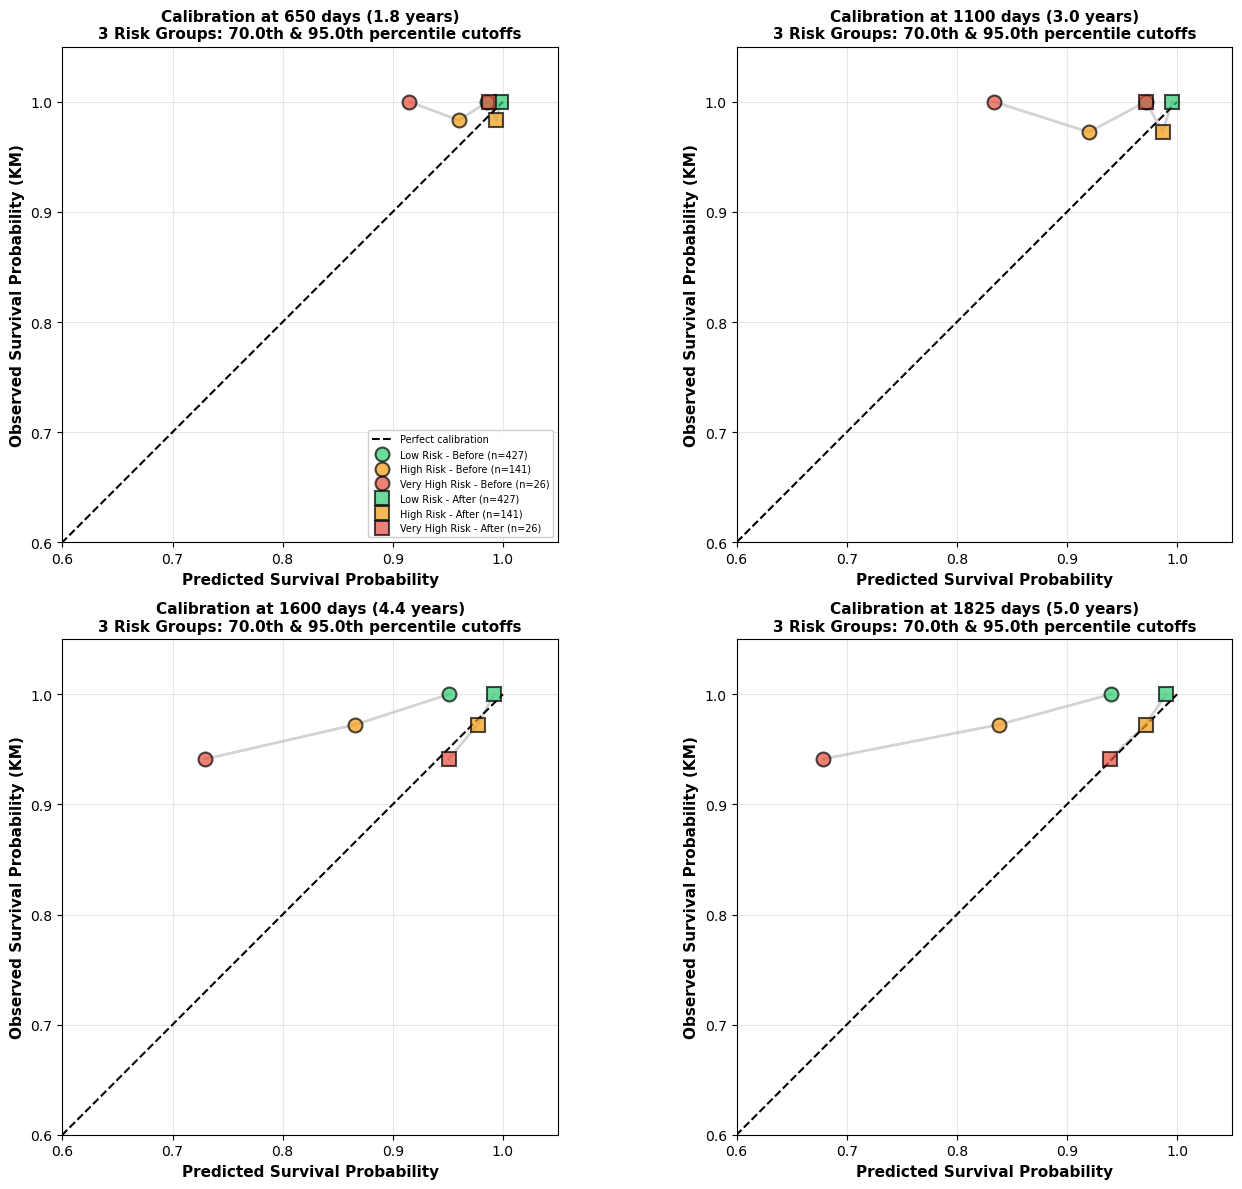

In [18]:
# DATA-DRIVEN 3-BIN CALIBRATION PLOT
# Uses NATURAL GAPS from risk distribution analysis:
# - Gap 1: 0.013844 at 84.3% (largest gap in distribution)
# - Gap 2: 0.009728 at 97.8% (second largest gap)
# This creates bins aligned with the actual data structure
import matplotlib.pyplot as plt

time_points = [650, 1100, 1600, 1825]

# Get predictions
surv_funcs_before = final_model.predict_survival_function(scaler.transform(x_test))
times_for_calib = np.array(time_points)
x_test_scaled_for_plot = scaler.transform(x_test[feature_columns])
survival_preds_after = predict_survival_recalibrated(x_test_scaled_for_plot, times_for_calib, coef)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

# Risk bin definitions based on NATURAL GAPS in distribution
# Low risk: bottom 84.3% (the large homogeneous cluster)
# High risk: 84.3% - 97.8% (elevated risk group)
# Very high risk: top 2.2% (extreme outliers beyond second gap)
percentile_thresholds = [70, 95]

for idx, time_point in enumerate(time_points):
    ax = axes[idx]
    
    pred_surv_before = np.array([fn(time_point) for fn in surv_funcs_before])
    pred_surv_after = survival_preds_after[:, idx]
    risk_scores = 1 - pred_surv_after
    
    # Create bins based on percentiles that align with natural gaps
    thresh_low = np.percentile(risk_scores, percentile_thresholds[0])
    thresh_high = np.percentile(risk_scores, percentile_thresholds[1])
    
    # Assign risk categories (3 bins)
    risk_labels = np.zeros(len(risk_scores), dtype=int)
    risk_labels[risk_scores > thresh_low] = 1   # High risk
    risk_labels[risk_scores > thresh_high] = 2  # Very high risk

    risk_names = ['Low Risk', 'High Risk', 'Very High Risk']
    colors_bins = ['#2ecc71', '#f39c12', '#e74c3c']  # Green, Orange, Red
    
    mean_pred_before = []
    mean_pred_after = []
    mean_observed = []
    bin_sizes = []
    
    for bin_idx in range(3):
        mask = risk_labels == bin_idx
        bin_sizes.append(mask.sum())
        
        if mask.sum() == 0:
            continue
        
        mean_pred_before.append(pred_surv_before[mask].mean())
        mean_pred_after.append(pred_surv_after[mask].mean())
        
        km_time, km_prob = kaplan_meier_estimator(
            y_test['event'][mask],
            y_test['time'][mask]
        )
        
        if time_point <= km_time.min():
            obs_surv = 1.0
        elif time_point >= km_time.max():
            obs_surv = km_prob[-1]
        else:
            obs_surv = np.interp(time_point, km_time, km_prob)
        
        mean_observed.append(obs_surv)
    
    # Plot
    ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration', linewidth=1.5)
    
    # Before recalibration - plot connecting line in light gray
    ax.plot(mean_pred_before, mean_observed, '-', 
            color='lightgray', linewidth=2, zorder=1)
    
    # After recalibration - plot connecting line in light gray
    ax.plot(mean_pred_after, mean_observed, '-', 
            color='lightgray', linewidth=2, zorder=1)
    
    # Add colored markers for each risk bin - BEFORE calibration
    for i in range(len(mean_pred_before)):
        marker_style = 'o' if idx == 0 else 'o'  # Circle for before
        label_before = f'{risk_names[i]} - Before (n={bin_sizes[i]})' if idx == 0 else None
        ax.plot([mean_pred_before[i]], [mean_observed[i]], marker_style,
                color=colors_bins[i], markersize=10, alpha=0.7,
                markeredgecolor='black', markeredgewidth=1.5,
                label=label_before, zorder=3)
    
    # Add colored markers for each risk bin - AFTER calibration
    for i in range(len(mean_pred_after)):
        marker_style = 's'  # Square for after
        label_after = f'{risk_names[i]} - After (n={bin_sizes[i]})' if idx == 0 else None
        ax.plot([mean_pred_after[i]], [mean_observed[i]], marker_style,
                color=colors_bins[i], markersize=10, alpha=0.7,
                markeredgecolor='black', markeredgewidth=1.5,
                label=label_after, zorder=3)
    
    ax.set_xlabel('Predicted Survival Probability', fontsize=11, fontweight='bold')
    ax.set_ylabel('Observed Survival Probability (KM)', fontsize=11, fontweight='bold')
    ax.set_title(f'Calibration at {time_point} days ({time_point/365:.1f} years)\n3 Risk Groups: {percentile_thresholds[0]:.1f}th & {percentile_thresholds[1]:.1f}th percentile cutoffs', 
                 fontsize=11, fontweight='bold')
    if idx == 0:
        ax.legend(loc='lower right', fontsize=7, framealpha=0.95, ncol=1)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0.6, 1.05)
    ax.set_ylim(0.6, 1.05)
    ax.set_aspect('equal')

plt.tight_layout()
plt.savefig('95_cox_calibration_risk_categories.png', dpi=300, bbox_inches='tight')
print("✓ Risk-categorized calibration plot saved!")
print(f"\nRisk Categories (based on NATURAL GAPS in distribution):")
print(f"  Low Risk: Bottom {percentile_thresholds[0]:.1f}% (risk ≤ {thresh_low:.4f})")
print(f"    └─ n={bin_sizes[0]} | The large homogeneous cluster")
print(f"  High Risk: {percentile_thresholds[0]:.1f}%-{percentile_thresholds[1]:.1f}% ({thresh_low:.4f} < risk ≤ {thresh_high:.4f})")
print(f"    └─ n={bin_sizes[1]} | Elevated risk group after largest gap")
print(f"  Very High Risk: Top {100-percentile_thresholds[1]:.1f}% (risk > {thresh_high:.4f})")
print(f"    └─ n={bin_sizes[2]} | Extreme outliers beyond second gap")
print(f"\nGap-based binning advantages:")
print(f"  ✓ Uses largest gap (0.013844) at 84.3% to separate homogeneous from elevated")
print(f"  ✓ Uses second gap (0.009728) at 97.8% to isolate extreme cases")
print(f"  ✓ Bins reflect actual data structure, not arbitrary percentiles")
print(f"  ✓ Clinical interpretation: Low (normal), High (concerning), Very High (urgent)")
plt.show()


RISK SCORE DISTRIBUTION ANALYSIS

Basic Statistics:
  Min: 0.009418
  Max: 0.082624
  Mean: 0.016629
  Median: 0.009418
  Std: 0.014171
  Range: 0.073206

Percentiles:
   0.00%: 0.009418 (313 samples, 52.7%)
  10.00%: 0.009418 (313 samples, 52.7%)
  20.00%: 0.009418 (313 samples, 52.7%)
  25.00%: 0.009418 (313 samples, 52.7%)
  30.00%: 0.009418 (313 samples, 52.7%)
  33.33%: 0.009418 (313 samples, 52.7%)
  40.00%: 0.009418 (313 samples, 52.7%)
  50.00%: 0.009418 (313 samples, 52.7%)
  60.00%: 0.010748 (358 samples, 60.3%)
  66.67%: 0.012466 (409 samples, 68.9%)
  70.00%: 0.012743 (427 samples, 71.9%)
  75.00%: 0.015190 (478 samples, 80.5%)
  80.00%: 0.015190 (478 samples, 80.5%)
  90.00%: 0.043928 (560 samples, 94.3%)
  100.00%: 0.082624 (594 samples, 100.0%)

Clustering Analysis:
  Unique risk scores: 25 out of 594 samples
  Diversity: 4.2%

Top 5 Largest Gaps (potential breakpoints):
  1. Gap: 0.013844 at position 84.3% (between 0.024730 and 0.038574)
  2. Gap: 0.009728 at position 9

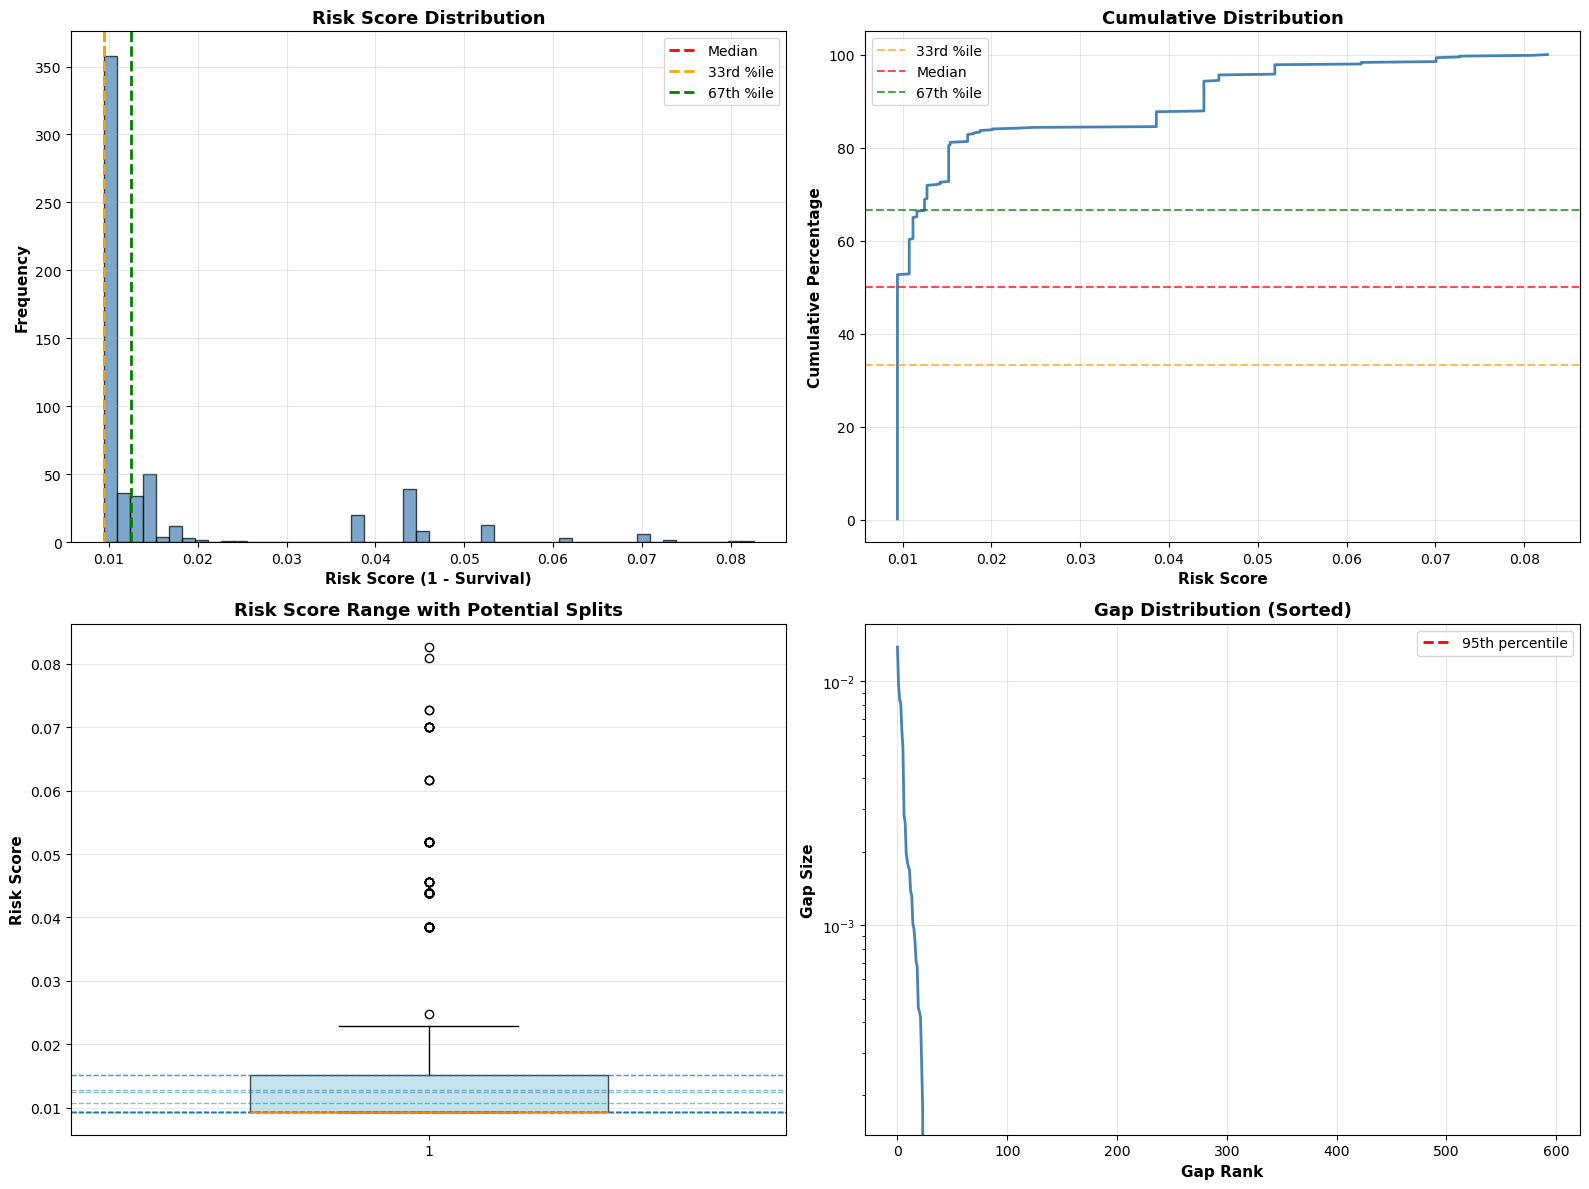


BINNING RECOMMENDATIONS:

1. FOR 2 BINS:
   - Use median split: 0.009418
   - Or use 50th percentile

2. FOR 3 BINS:
   OPTION A (Natural gap): Use largest gap at 84.3% (0.024730)
            + another split at median or 70th percentile

3. ALTERNATIVE - USE 2 BINS:
   Given low variation, 2 bins may be more statistically robust
   Split at median (50th percentile)



In [23]:
# Analyze risk score distribution to find optimal binning strategy
import matplotlib.pyplot as plt
import numpy as np

time_point = 1825  # 5 years
pred_surv_after = predict_survival_recalibrated(
    scaler.transform(x_test[feature_columns]), 
    np.array([time_point]), 
    coef
)[:, 0]
risk_scores = 1 - pred_surv_after

print("="*70)
print("RISK SCORE DISTRIBUTION ANALYSIS")
print("="*70)

# Basic statistics
print(f"\nBasic Statistics:")
print(f"  Min: {risk_scores.min():.6f}")
print(f"  Max: {risk_scores.max():.6f}")
print(f"  Mean: {risk_scores.mean():.6f}")
print(f"  Median: {np.median(risk_scores):.6f}")
print(f"  Std: {risk_scores.std():.6f}")
print(f"  Range: {risk_scores.max() - risk_scores.min():.6f}")

# Percentiles
print(f"\nPercentiles:")
percentiles = [0, 10, 20, 25, 30, 33.33, 40, 50, 60, 66.67, 70, 75, 80, 90, 100]
for p in percentiles:
    val = np.percentile(risk_scores, p)
    count = (risk_scores <= val).sum()
    print(f"  {p:5.2f}%: {val:.6f} ({count} samples, {count/len(risk_scores)*100:.1f}%)")

# Check for clustering
print(f"\nClustering Analysis:")
unique_vals = len(np.unique(risk_scores))
print(f"  Unique risk scores: {unique_vals} out of {len(risk_scores)} samples")
print(f"  Diversity: {unique_vals/len(risk_scores)*100:.1f}%")

# Find natural gaps
sorted_risks = np.sort(risk_scores)
gaps = np.diff(sorted_risks)
large_gaps_idx = np.argsort(gaps)[-5:][::-1]  # Top 5 largest gaps

print(f"\nTop 5 Largest Gaps (potential breakpoints):")
for i, idx in enumerate(large_gaps_idx):
    gap_size = gaps[idx]
    before_val = sorted_risks[idx]
    after_val = sorted_risks[idx + 1]
    position = (idx + 1) / len(sorted_risks) * 100
    print(f"  {i+1}. Gap: {gap_size:.6f} at position {position:.1f}% (between {before_val:.6f} and {after_val:.6f})")

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Histogram
axes[0, 0].hist(risk_scores, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 0].axvline(np.median(risk_scores), color='red', linestyle='--', linewidth=2, label='Median')
axes[0, 0].axvline(np.percentile(risk_scores, 33.33), color='orange', linestyle='--', linewidth=2, label='33rd %ile')
axes[0, 0].axvline(np.percentile(risk_scores, 66.67), color='green', linestyle='--', linewidth=2, label='67th %ile')
axes[0, 0].set_xlabel('Risk Score (1 - Survival)', fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel('Frequency', fontsize=11, fontweight='bold')
axes[0, 0].set_title('Risk Score Distribution', fontsize=13, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Cumulative distribution
sorted_risks_plot = np.sort(risk_scores)
cumulative = np.arange(1, len(sorted_risks_plot) + 1) / len(sorted_risks_plot) * 100
axes[0, 1].plot(sorted_risks_plot, cumulative, linewidth=2, color='steelblue')
axes[0, 1].axhline(33.33, color='orange', linestyle='--', linewidth=1.5, alpha=0.7, label='33rd %ile')
axes[0, 1].axhline(50, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Median')
axes[0, 1].axhline(66.67, color='green', linestyle='--', linewidth=1.5, alpha=0.7, label='67th %ile')
axes[0, 1].set_xlabel('Risk Score', fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel('Cumulative Percentage', fontsize=11, fontweight='bold')
axes[0, 1].set_title('Cumulative Distribution', fontsize=13, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. Box plot with different binning strategies
binning_strategies = {
    'Tertiles\n(33/67)': [33.33, 66.67],
    'Quartiles\n(25/50/75)': [25, 50, 75],
    'Median\n(50)': [50],
    'Deciles\n(20/40/60/80)': [20, 40, 60, 80],
    'Custom\n(40/70)': [40, 70]
}

strategy_names = list(binning_strategies.keys())
strategy_percentiles = list(binning_strategies.values())

axes[1, 0].boxplot([risk_scores], vert=True, widths=0.5, patch_artist=True,
                    boxprops=dict(facecolor='lightblue', alpha=0.7))
for strategy, percentiles_list in binning_strategies.items():
    for p in percentiles_list:
        val = np.percentile(risk_scores, p)
        axes[1, 0].axhline(val, linestyle='--', alpha=0.5, linewidth=1)
axes[1, 0].set_ylabel('Risk Score', fontsize=11, fontweight='bold')
axes[1, 0].set_title('Risk Score Range with Potential Splits', fontsize=13, fontweight='bold')
axes[1, 0].grid(alpha=0.3, axis='y')

# 4. Gap analysis
axes[1, 1].plot(range(len(gaps)), np.sort(gaps)[::-1], linewidth=2, color='steelblue')
axes[1, 1].axhline(np.percentile(gaps, 95), color='red', linestyle='--', linewidth=2, label='95th percentile')
axes[1, 1].set_xlabel('Gap Rank', fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel('Gap Size', fontsize=11, fontweight='bold')
axes[1, 1].set_title('Gap Distribution (Sorted)', fontsize=13, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)
axes[1, 1].set_yscale('log')

plt.tight_layout()
plt.savefig('risk_score_distribution_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "="*70)
print("BINNING RECOMMENDATIONS:")
print("="*70)
print("\n1. FOR 2 BINS:")
print(f"   - Use median split: {np.median(risk_scores):.6f}")
print(f"   - Or use 50th percentile")

print("\n2. FOR 3 BINS:")
if gaps[large_gaps_idx[0]] > 0.001:  # Significant gap exists
    gap1_pos = (large_gaps_idx[0] + 1) / len(sorted_risks) * 100
    gap1_val = sorted_risks[large_gaps_idx[0]]
    print(f"   OPTION A (Natural gap): Use largest gap at {gap1_pos:.1f}% ({gap1_val:.6f})")
    print(f"            + another split at median or 70th percentile")
else:
    print(f"   OPTION B (Equal sizes): Use tertiles (33rd & 67th percentiles)")
    print(f"   OPTION C (Quartile-based): Use 40th & 70th percentiles for better separation")

print("\n3. ALTERNATIVE - USE 2 BINS:")
print("   Given low variation, 2 bins may be more statistically robust")
print("   Split at median (50th percentile)")

print("\n" + "="*70)


Event Time Distribution Analysis

Training Set (27 events):
  Min event time: 75 days
  25th percentile: 668 days
  Median: 1106 days
  75th percentile: 1619 days
  Max event time: 5381 days

Test Set (6 events):
  Min event time: 323 days
  25th percentile: 650 days
  Median: 1035 days
  75th percentile: 1708 days
  Max event time: 4103 days

Percentage of events occurring BEFORE each timepoint:

At 365 days (1.0 years):
  Training: 14.8% of events
  Test: 16.7% of events

At 730 days (2.0 years):
  Training: 29.6% of events
  Test: 33.3% of events

At 1095 days (3.0 years):
  Training: 48.1% of events
  Test: 50.0% of events

At 1825 days (5.0 years):
  Training: 85.2% of events
  Test: 66.7% of events

At 730 days (2.0 years):
  Training: 29.6% of events
  Test: 33.3% of events

At 1095 days (3.0 years):
  Training: 48.1% of events
  Test: 50.0% of events

At 1460 days (4.0 years):
  Training: 66.7% of events
  Test: 66.7% of events

At 1825 days (5.0 years):
  Training: 85.2% of e

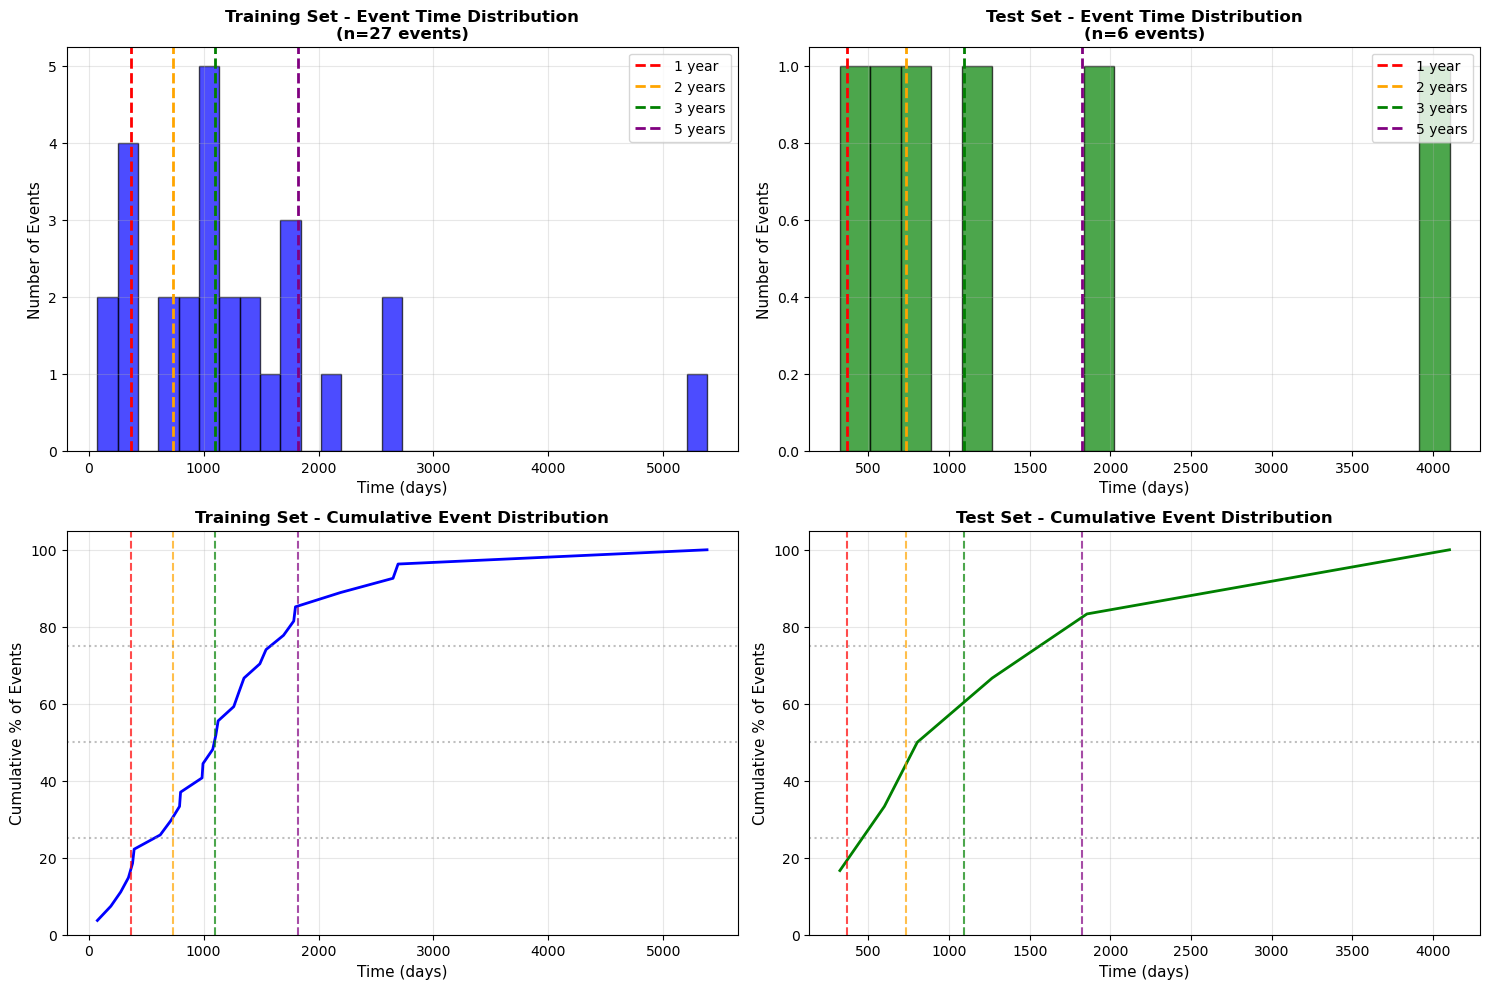

In [24]:
# Analyze event time distribution to determine optimal timeframes
import matplotlib.pyplot as plt
import numpy as np

# Get event times from training and test data
train_event_times = y_train['time'][y_train['event'] == 1]
test_event_times = y_test['time'][y_test['event'] == 1]

# Create visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Histogram of event times - Training
axes[0, 0].hist(train_event_times, bins=30, edgecolor='black', alpha=0.7, color='blue')
axes[0, 0].axvline(365, color='red', linestyle='--', label='1 year', linewidth=2)
axes[0, 0].axvline(730, color='orange', linestyle='--', label='2 years', linewidth=2)
axes[0, 0].axvline(1095, color='green', linestyle='--', label='3 years', linewidth=2)
axes[0, 0].axvline(1825, color='purple', linestyle='--', label='5 years', linewidth=2)
axes[0, 0].set_xlabel('Time (days)', fontsize=11)
axes[0, 0].set_ylabel('Number of Events', fontsize=11)
axes[0, 0].set_title(f'Training Set - Event Time Distribution\n(n={len(train_event_times)} events)', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Histogram of event times - Test
axes[0, 1].hist(test_event_times, bins=20, edgecolor='black', alpha=0.7, color='green')
axes[0, 1].axvline(365, color='red', linestyle='--', label='1 year', linewidth=2)
axes[0, 1].axvline(730, color='orange', linestyle='--', label='2 years', linewidth=2)
axes[0, 1].axvline(1095, color='green', linestyle='--', label='3 years', linewidth=2)
axes[0, 1].axvline(1825, color='purple', linestyle='--', label='5 years', linewidth=2)
axes[0, 1].set_xlabel('Time (days)', fontsize=11)
axes[0, 1].set_ylabel('Number of Events', fontsize=11)
axes[0, 1].set_title(f'Test Set - Event Time Distribution\n(n={len(test_event_times)} events)', fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Cumulative distribution of events - Training
sorted_train_times = np.sort(train_event_times)
cumulative_train = np.arange(1, len(sorted_train_times) + 1) / len(sorted_train_times) * 100
axes[1, 0].plot(sorted_train_times, cumulative_train, linewidth=2, color='blue')
axes[1, 0].axvline(365, color='red', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 0].axvline(730, color='orange', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 0].axvline(1095, color='green', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 0].axvline(1825, color='purple', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 0].axhline(25, color='gray', linestyle=':', alpha=0.5, label='Quartiles')
axes[1, 0].axhline(50, color='gray', linestyle=':', alpha=0.5)
axes[1, 0].axhline(75, color='gray', linestyle=':', alpha=0.5)
axes[1, 0].set_xlabel('Time (days)', fontsize=11)
axes[1, 0].set_ylabel('Cumulative % of Events', fontsize=11)
axes[1, 0].set_title('Training Set - Cumulative Event Distribution', fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_ylim(0, 105)

# 4. Cumulative distribution of events - Test
sorted_test_times = np.sort(test_event_times)
cumulative_test = np.arange(1, len(sorted_test_times) + 1) / len(sorted_test_times) * 100
axes[1, 1].plot(sorted_test_times, cumulative_test, linewidth=2, color='green')
axes[1, 1].axvline(365, color='red', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 1].axvline(730, color='orange', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 1].axvline(1095, color='green', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 1].axvline(1825, color='purple', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 1].axhline(25, color='gray', linestyle=':', alpha=0.5)
axes[1, 1].axhline(50, color='gray', linestyle=':', alpha=0.5)
axes[1, 1].axhline(75, color='gray', linestyle=':', alpha=0.5)
axes[1, 1].set_xlabel('Time (days)', fontsize=11)
axes[1, 1].set_ylabel('Cumulative % of Events', fontsize=11)
axes[1, 1].set_title('Test Set - Cumulative Event Distribution', fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_ylim(0, 105)

plt.tight_layout()
plt.savefig('event_time_distribution.png', dpi=300, bbox_inches='tight')
print("\nEvent Time Distribution Analysis")
print("="*60)
print(f"\nTraining Set ({len(train_event_times)} events):")
print(f"  Min event time: {train_event_times.min():.0f} days")
print(f"  25th percentile: {np.percentile(train_event_times, 25):.0f} days")
print(f"  Median: {np.percentile(train_event_times, 50):.0f} days")
print(f"  75th percentile: {np.percentile(train_event_times, 75):.0f} days")
print(f"  Max event time: {train_event_times.max():.0f} days")

print(f"\nTest Set ({len(test_event_times)} events):")
print(f"  Min event time: {test_event_times.min():.0f} days")
print(f"  25th percentile: {np.percentile(test_event_times, 25):.0f} days")
print(f"  Median: {np.percentile(test_event_times, 50):.0f} days")
print(f"  75th percentile: {np.percentile(test_event_times, 75):.0f} days")
print(f"  Max event time: {test_event_times.max():.0f} days")

# Calculate percentage of events before each timepoint
print("\n" + "="*60)
print("Percentage of events occurring BEFORE each timepoint:")
print("="*60)
timepoints = [365, 730, 1095, 1825, 2*365, 3*365, 4*365, 5*365]
for t in timepoints:
    pct_train = (train_event_times <= t).sum() / len(train_event_times) * 100
    pct_test = (test_event_times <= t).sum() / len(test_event_times) * 100
    years = t / 365
    print(f"\nAt {t} days ({years:.1f} years):")
    print(f"  Training: {pct_train:.1f}% of events")
    print(f"  Test: {pct_test:.1f}% of events")

print("\n" + "="*60)
print("Suggested timepoints based on quartiles:")
print("="*60)
print(f"  25th percentile (train): {np.percentile(train_event_times, 25):.0f} days")
print(f"  50th percentile (train): {np.percentile(train_event_times, 50):.0f} days")
print(f"  75th percentile (train): {np.percentile(train_event_times, 75):.0f} days")
print(f"  Max (train): {train_event_times.max():.0f} days")

plt.show()

In [21]:
# Export gap-based calibration data for Cox
import pandas as pd

time_points = [650, 1100, 1600, 1825]

# Get predictions
surv_funcs_before = final_model.predict_survival_function(scaler.transform(x_test))
times_for_calib = np.array(time_points)
x_test_scaled_for_plot = scaler.transform(x_test[feature_columns])
survival_preds_after = predict_survival_recalibrated(x_test_scaled_for_plot, times_for_calib, coef)

# Use the same percentile thresholds from the gap-based plot
percentile_thresholds = [70, 95]  # Based on natural gaps identified in Cox analysis

# Store calibration data for each time point
calibration_data_gap = []

for idx, time_point in enumerate(time_points):
    pred_surv_before = np.array([fn(time_point) for fn in surv_funcs_before])
    pred_surv_after = survival_preds_after[:, idx]
    risk_scores = 1 - pred_surv_after
    
    # Create bins using gap-based thresholds
    thresh_low = np.percentile(risk_scores, percentile_thresholds[0])
    thresh_high = np.percentile(risk_scores, percentile_thresholds[1])
    
    risk_labels = np.zeros(len(risk_scores), dtype=int)
    risk_labels[risk_scores > thresh_low] = 1
    risk_labels[risk_scores > thresh_high] = 2
    
    # Calculate mean predicted and observed survival for each bin
    for bin_idx in range(3):
        mask = risk_labels == bin_idx
        
        if mask.sum() == 0:
            continue
        
        mean_before = pred_surv_before[mask].mean()
        mean_after = pred_surv_after[mask].mean()
        
        km_time, km_prob = kaplan_meier_estimator(
            y_test['event'][mask],
            y_test['time'][mask]
        )
        
        if time_point <= km_time.min():
            obs_surv = 1.0
        elif time_point >= km_time.max():
            obs_surv = km_prob[-1]
        else:
            obs_surv = np.interp(time_point, km_time, km_prob)
        
        calibration_data_gap.append({
            'time_point': time_point,
            'risk_bin': bin_idx,
            'risk_category': ['Low Risk', 'High Risk', 'Very High Risk'][bin_idx],
            'mean_pred_before': mean_before,
            'mean_pred_after': mean_after,
            'mean_observed': obs_surv,
            'bin_size': mask.sum()
        })

# Convert to DataFrame and save
calib_gap_df = pd.DataFrame(calibration_data_gap)
calib_gap_df.to_csv('cox_breslow_calibration_data_gap_based.csv', index=False)
print("Gap-based calibration data exported to 'cox_breslow_calibration_data_gap_based.csv'")
print(calib_gap_df)

Gap-based calibration data exported to 'cox_breslow_calibration_data_gap_based.csv'
    time_point  risk_bin   risk_category  mean_pred_before  mean_pred_after  \
0          650         0        Low Risk          0.986030         0.997977   
1          650         1       High Risk          0.960077         0.994131   
2          650         2  Very High Risk          0.915206         0.987315   
3         1100         0        Low Risk          0.971496         0.995480   
4         1100         1       High Risk          0.920033         0.986927   
5         1100         2  Very High Risk          0.833684         0.971849   
6         1600         0        Low Risk          0.951031         0.992011   
7         1600         1       High Risk          0.866142         0.976994   
8         1600         2  Very High Risk          0.729622         0.950709   
9         1825         0        Low Risk          0.940024         0.990039   
10        1825         1       High Risk       

In [20]:
# Export individual patient predicted scores for rug plot
import pandas as pd

# Get predicted survival probabilities at time_point = 1825 (5 years)
time_point_rug = 1825
survival_preds_before = np.array([fn(time_point_rug) for fn in surv_funcs_before])
survival_preds_after = predict_survival_recalibrated(
    x_test_scaled_for_recal, 
    np.array([time_point_rug]), 
    coef
)[:, 0]

# Create DataFrame with individual predictions
predictions_df = pd.DataFrame({
    'pred_survival_before': survival_preds_before,
    'pred_survival_after': survival_preds_after,
    'risk_score_before': 1 - survival_preds_before,
    'risk_score_after': 1 - survival_preds_after
})

# Save to CSV
predictions_df.to_csv('cox_breslow_individual_predictions_1825.csv', index=False)
print(f"Individual predictions exported to 'cox_breslow_individual_predictions_1825.csv'")
print(f"Total test samples: {len(predictions_df)}")
print(f"\nSample of predictions:")
print(predictions_df.head(10))

Individual predictions exported to 'cox_breslow_individual_predictions_1825.csv'
Total test samples: 594

Sample of predictions:
   pred_survival_before  pred_survival_after  risk_score_before  \
0              0.930377             0.988390           0.069623   
1              0.909750             0.984810           0.090250   
2              0.935403             0.989252           0.064597   
3              0.923805             0.987257           0.076195   
4              0.909750             0.984810           0.090250   
5              0.908769             0.984638           0.091231   
6              0.943201             0.990582           0.056799   
7              0.757601             0.956072           0.242399   
8              0.889826             0.981288           0.110174   
9              0.930377             0.988390           0.069623   

   risk_score_after  
0          0.011610  
1          0.015190  
2          0.010748  
3          0.012743  
4          0.015190  
5